# 05 - Comparación de modelos

Hasta ahora el asistente ha usado siempre el mismo modelo de lenguaje, gpt-oss-120b. En este cuaderno probamos un segundo modelo, más pequeño y de otra familia, y medimos si responde igual de bien y cuánto tarda.

Para que la comparación sea justa, todo lo demás es igual que en el cuaderno 04: las mismas 10 preguntas, la misma búsqueda con re-ranking, el mismo prompt y la misma temperatura. Para cada pregunta se buscan los trozos una sola vez y esos mismos trozos se les dan a los dos modelos, así que lo único que cambia es el LLM.

# Los dos modelos

| | gpt-oss-120b | qwen3.8-27b |
|---|---|---|
| Familia | OpenAI | Alibaba (Qwen) |
| Tamaño (miles de millones de parámetros) | unos 120 | 27 |
| Estado en Groq | Producción | Preview (pueden retirarlo con poco aviso) |
| Límite del plan gratuito | 8.000 tokens por minuto | 8.000 tokens por minuto |

Elegimos **qwen3.8-27b** porque en el plan gratuito de Groq es el único modelo de chat de otra familia pensado para varios idiomas: los Llama solo están disponibles para cuentas Enterprise y allam-2-7b está hecho para árabe e inglés. Al seguir en Groq no hay que cambiar nada de la infraestructura.

# Importaciones

Las mismas del cuaderno 04 y, además, **genai** (de Google): el cliente para hablar con los modelos de Gemini, que usaremos como jueces.

In [1]:
import os
import time
from dotenv import load_dotenv
import chromadb
from sentence_transformers import SentenceTransformer, CrossEncoder
from groq import Groq
from google import genai
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

W1113 15:28:21.163000 62868 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


# Carga de las claves, Chroma, embeddings y re-ranker

Igual que en el cuaderno 04. La novedad es una segunda clave, la de Gemini, que también está en el archivo .env y tampoco se muestra.

In [2]:
load_dotenv('../.env')
print('Clave de Groq cargada:', os.getenv('GROQ_API_KEY') is not None)
print('Clave de Gemini cargada:', os.getenv('GEMINI_API_KEY') is not None)

Clave de Groq cargada: True
Clave de Gemini cargada: True


In [3]:
client = chromadb.PersistentClient(path='../chroma_db')
collection = client.get_collection('taller')
collection.count()

850

In [4]:
model = SentenceTransformer('intfloat/multilingual-e5-small')
reranker = CrossEncoder('cross-encoder/mmarco-mMiniLMv2-L12-H384-v1')
cliente = Groq(api_key=os.getenv('GROQ_API_KEY'))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

El cliente de Google se crea con dos opciones:

- **api_version v1beta:** el modelo de decisiones que usamos como segundo juez solo está disponible en esa versión de la API.
- **retry_options con un solo intento:** por defecto, cuando una llamada falla, la librería de Google la repite varias veces por su cuenta sin avisar, y desde fuera parece que el cuaderno se ha quedado colgado. Con un solo intento el error se ve al momento. Los reintentos los hacemos nosotros en las funciones de los jueces, a la vista.

In [5]:
cliente_google = genai.Client(api_key=os.getenv('GEMINI_API_KEY'),
                              http_options={'api_version': 'v1beta', 'retry_options': {'attempts': 1}})

# Búsqueda con re-ranking

Las dos funciones del cuaderno 04, sin cambios: e5 trae 20 candidatos, el cross-encoder los puntúa y nos quedamos con los 4 mejores.

In [6]:
def buscar_basico(pregunta, k=4):
    vector = model.encode('query: ' + pregunta, normalize_embeddings=True).tolist()
    resultados = collection.query(query_embeddings=[vector], n_results=k)
    trozos = resultados['documents'][0]
    fuentes = []
    for metadato in resultados['metadatas'][0]:
        fuentes.append(metadato['fuente'])
    return trozos, fuentes

In [7]:
def buscar_reranking(pregunta, candidatos=20, k=4):
    trozos, fuentes = buscar_basico(pregunta, k=candidatos)
    parejas = []
    for trozo in trozos:
        parejas.append([pregunta, trozo])
    puntuaciones = reranker.predict(parejas, show_progress_bar=False)
    orden = np.argsort(puntuaciones)[::-1]
    mejores_trozos = []
    mejores_fuentes = []
    for i in orden[:k]:
        mejores_trozos.append(trozos[i])
        mejores_fuentes.append(fuentes[i])
    return mejores_trozos, mejores_fuentes

# Prompt y generación

construir_prompt y el prompt de sistema son los mismos del cuaderno 04.

In [8]:
def construir_prompt(pregunta, trozos, fuentes):
    contexto = ''
    for i in range(len(trozos)):
        contexto = contexto + '[' + str(i + 1) + '] Fuente: ' + fuentes[i] + '\n' + trozos[i] + '\n\n'
    prompt = 'Contexto:\n' + contexto + 'Pregunta: ' + pregunta
    return prompt

In [9]:
prompt_sistema = '''Eres el asistente de un taller de vehículos en España.
Responde en español, de forma breve y clara, usando SOLO la información del contexto.
Indica al final la fuente o fuentes que has usado (el nombre del archivo).
Si el contexto no contiene la respuesta, di exactamente: No lo sé con la información disponible.'''

## Los modelos y la función generar

Guardamos el nombre de cada modelo en una variable. La función generar es la del cuaderno 04 con dos cambios:

- Recibe el nombre del modelo, para poder llamar a cualquiera de los dos con el mismo código.
- Mide el tiempo: time.time() da la hora en segundos, así que restando la hora de antes y la de después de la llamada sabemos cuánto ha tardado. La pausa de 15 segundos queda fuera de la medida.

Devuelve tres cosas: el texto de la respuesta, los segundos y los tokens de salida, que Groq informa en usage. Los tokens de salida incluyen lo que el modelo escribe mientras razona, aunque no se vea en la respuesta, y ayudan a entender las diferencias de tiempo.

Cada modelo se usa como viene de serie, sin tocar su modo de razonamiento. Mantenemos la pausa de 15 segundos del cuaderno 04: el límite de 8.000 tokens por minuto se aplica a cada modelo por separado.

In [10]:
modelo_gpt = 'openai/gpt-oss-120b'
modelo_qwen = 'qwen/qwen3.8-27b'

In [11]:
def generar(modelo, pregunta, trozos, fuentes):
    prompt = construir_prompt(pregunta, trozos, fuentes)
    inicio = time.time()
    respuesta = cliente.chat.completions.create(
        model=modelo,
        temperature=0.1,
        messages=[{'role': 'system', 'content': prompt_sistema},
                  {'role': 'user', 'content': prompt}])
    segundos = time.time() - inicio
    time.sleep(15)
    return respuesta.choices[0].message.content, segundos, respuesta.usage.completion_tokens

# Prueba rápida

Antes de evaluar, probamos la función con una pregunta del cuaderno 03 que no está en el conjunto de evaluación.

In [12]:
pregunta = '¿Cada cuánto tiene que pasar la ITV un turismo particular?'
trozos, fuentes = buscar_reranking(pregunta)
print('Fuentes:', fuentes)

for modelo in [modelo_gpt, modelo_qwen]:
    texto, segundos, tokens = generar(modelo, pregunta, trozos, fuentes)
    print()
    print('=' * 60)
    print(modelo, '-', round(segundos, 2), 'segundos -', tokens, 'tokens de salida')
    print(texto)

Fuentes: ['faq_taller.md', 'rd_920_2017_inspeccion_tecnica_vehiculos.xml', 'rd_920_2017_inspeccion_tecnica_vehiculos.html', 'rd_920_2017_inspeccion_tecnica_vehiculos.xml']



openai/gpt-oss-120b - 0.84 segundos - 183 tokens de salida
Un turismo de uso particular está exento de la ITV los primeros 4 años; después debe pasarla cada 2 años hasta que cumpla 10 años, y a partir de ese momento debe revisarse **anualmente**.  

**Fuente:** faq_taller.md



qwen/qwen3.8-27b - 0.38 segundos - 58 tokens de salida
Un turismo de uso particular está exento de pasar la ITV los cuatro primeros años. A partir de entonces, debe pasarla cada dos años hasta los diez años de antigüedad, y a partir de los diez años, cada año.

Fuente: faq_taller.md


# Conjunto de evaluación

Las mismas 10 preguntas del cuaderno 04, con su fuente, su dato y su respuesta de referencia.

In [13]:
preguntas = [
    {'pregunta': '¿Abre el taller los sábados?',
     'fuente': ['faq_taller.md'], 'dato': '9:00 a 13:00',
     'referencia': 'Sí, los sábados de 9:00 a 13:00, solo para entregas y recogidas.'},
    {'pregunta': '¿Cuándo es gratis el coche de sustitución?',
     'fuente': ['faq_taller.md'], 'dato': '300',
     'referencia': 'Es gratuito en reparaciones de más de 300 €; en el resto cuesta 20 € al día.'},
    {'pregunta': '¿Cuánto dura la garantía de una reparación en un taller?',
     'fuente': ['rd_1457_1986_talleres_reparacion.pdf', 'faq_taller.md'], 'dato': '2.000',
     'referencia': 'Tres meses o 2.000 kilómetros (en vehículos industriales, quince días o 2.000 kilómetros).'},
    {'pregunta': '¿Dónde tiene que poner un taller la placa-distintivo?',
     'fuente': ['rd_1457_1986_talleres_reparacion.pdf'], 'dato': 'fachada',
     'referencia': 'En la fachada del edificio, en un lugar fácilmente visible.'},
    {'pregunta': '¿En qué plazo hay que reparar los defectos leves detectados en la ITV?',
     'fuente': ['rd_920_2017_inspeccion_tecnica_vehiculos.html', 'rd_920_2017_inspeccion_tecnica_vehiculos.xml'], 'dato': 'dos meses',
     'referencia': 'En un plazo máximo de dos meses, sin necesidad de nueva inspección.'},
    {'pregunta': '¿Qué resultado tiene la ITV si se detecta un defecto muy grave?',
     'fuente': ['rd_920_2017_inspeccion_tecnica_vehiculos.html', 'rd_920_2017_inspeccion_tecnica_vehiculos.xml'], 'dato': 'negativo',
     'referencia': 'El resultado de la inspección es negativo.'},
    {'pregunta': '¿Cómo puedo consultar si mi coche tiene una llamada a revisión pendiente?',
     'fuente': ['dgt_llamadas_a_revision.html'], 'dato': 'Cl@ve',
     'referencia': 'En el servicio de la DGT, identificándose con certificado o credenciales Cl@ve.'},
    {'pregunta': '¿Qué estaciones ITV hay en la provincia de Valladolid?',
     'fuente': ['registro_estaciones_itv_2026.csv'], 'dato': '(Valladolid,',
     'referencia': 'Valladolid (4701 y 4703), Tordesillas (4702), Medina de Rioseco (4704), Peñafiel (4705) y las unidades móviles 47A2 y 47A3.'},
    {'pregunta': '¿Hay alguna estación ITV en Utrera?',
     'fuente': ['registro_estaciones_itv_2026.csv'], 'dato': 'UTRERA',
     'referencia': 'Sí, la estación 4131, en Utrera (Sevilla).'},
    {'pregunta': '¿Quién ganó el Mundial de fútbol de 2010?',
     'fuente': [], 'dato': '',
     'referencia': 'No lo sé con la información disponible.'}
]
len(preguntas)

10

# Métricas

## 1. Acierto de recuperación

La misma función del cuaderno 04. Como los dos modelos reciben los mismos trozos, esta métrica vale lo mismo para los dos: la calculamos una vez, solo para saber en qué preguntas la búsqueda no ha traído la información.

In [14]:
def acierto_recuperacion(trozos, fuentes, fuente_esperada, dato):
    for i in range(len(trozos)):
        if fuentes[i] in fuente_esperada and dato.lower() in trozos[i].lower():
            return 1
    return 0

## 2. Respuesta correcta (juez: Gemini 3.5 Flash-Lite)

En el cuaderno 04 el juez era gpt-oss-120b. Aquí ese modelo es uno de los dos que se comparan, y no parece justo que califique sus propias respuestas. Por eso el juez es de una tercera familia, Gemini (Google), que tiene nivel gratuito.

La primera idea fue usar Gemini 4 Hydrogen, el modelo gratuito más capaz de Google. No sirvió: su nivel gratuito solo permite 20 peticiones al día y una evaluación son justo 20 calificaciones, así que una sola ejecución agota el día. Usamos **Gemini 3.5 Flash-Lite**, más pequeño pero con cuota suficiente, y lo compensamos con un segundo juez (más abajo) y con la revisión manual.

El criterio y el prompt del juez son exactamente los del cuaderno 04, y también la temperatura 0. Cambia solo la forma de llamarlo: interactions.create es la función de la librería de Google para pedir un texto; las instrucciones van en system_instruction, el mensaje en input y la temperatura en generation_config.

## Por qué el juez lleva reintentos

Un servicio gratuito puede fallar en cualquier llamada: por cuota agotada, por saturación o por tardar demasiado. En las primeras ejecuciones de este cuaderno la evaluación se quedaba colgada sin dar ningún error. Para que el fallo se vea y no pare todo, la función juzgar hace tres cosas:

- **timeout=30:** si el juez no contesta en 30 segundos, se corta la llamada.
- **try / except:** try intenta la llamada y, si falla, en vez de parar el cuaderno con un error se ejecuta lo que hay en except, que aquí es avisar del tipo de error y esperar 15 segundos.
- **Hasta 3 intentos:** el bucle while repite la llamada mientras no haya respuesta. Si después de 3 intentos sigue sin contestar, la función devuelve nan (sin calificar) en lugar de inventarse una nota.

Después de cada calificación hay una pausa de 5 segundos para no saturar el nivel gratuito. Nada de esto afecta a la comparación: el tiempo que medimos es el de los modelos de Groq, no el del juez.

In [15]:
prompt_juez = '''Eres un evaluador. Compara la RESPUESTA con la REFERENCIA.
Responde CORRECTO si la respuesta contiene la información esencial de la referencia y no la contradice.
Responde INCORRECTO si le falta un dato clave, lo contradice, o dice que no lo sabe cuando la referencia sí da una respuesta.
Contesta solo con una palabra: CORRECTO o INCORRECTO.'''

def juzgar(pregunta, respuesta, referencia):
    mensaje = 'PREGUNTA: ' + pregunta + '\nREFERENCIA: ' + referencia + '\nRESPUESTA: ' + respuesta
    salida = None
    intentos = 0
    while salida is None and intentos < 3:
        try:
            salida = cliente_google.interactions.create(
                model='gemini-3.5-flash-lite',
                system_instruction=prompt_juez,
                input=mensaje,
                generation_config={'temperature': 0},
                timeout=30)
        except Exception as error:
            print('El juez ha fallado (' + type(error).__name__ + '); esperamos 15 segundos y lo reintentamos')
            time.sleep(15)
        intentos = intentos + 1
    time.sleep(5)
    if salida is None:
        return np.nan
    texto = salida.output_text.upper()
    if 'INCORRECTO' in texto:
        return 0
    return 1

## 3. Tiempo de respuesta

Son los segundos que mide la función generar en cada llamada: lo que espera el usuario desde que se envía el prompt hasta que llega la respuesta completa. Calculamos la media y la mediana por modelo. La mediana es el valor central y no se deja arrastrar por una llamada suelta que tarde mucho.

Es una medida orientativa: depende también de la conexión y de lo ocupados que estén los servidores de Groq en ese momento.

# Evaluación

La hacemos en dos pasos separados: primero se generan las 20 respuestas y después se califican. Así, si el juez falla, las respuestas ya generadas no se pierden y basta con repetir la segunda celda.

## Paso 1: generar las respuestas

Recorremos las 10 preguntas. Para cada una buscamos los trozos con re-ranking una sola vez y generamos la respuesta con los dos modelos, guardando el texto, los segundos y los tokens.

Por las pausas, esta celda tarda unos 6 minutos (20 llamadas a Groq).

In [16]:
filas = []
for p in preguntas:
    trozos, fuentes = buscar_reranking(p['pregunta'])
    texto_gpt, segundos_gpt, tokens_gpt = generar(modelo_gpt, p['pregunta'], trozos, fuentes)
    texto_qwen, segundos_qwen, tokens_qwen = generar(modelo_qwen, p['pregunta'], trozos, fuentes)
    fila = {'pregunta': p['pregunta'], 'referencia': p['referencia']}
    if len(p['fuente']) > 0:
        fila['recuperacion'] = acierto_recuperacion(trozos, fuentes, p['fuente'], p['dato'])
    else:
        fila['recuperacion'] = np.nan
    fila['seg_gpt'] = segundos_gpt
    fila['seg_qwen'] = segundos_qwen
    fila['tokens_gpt'] = tokens_gpt
    fila['tokens_qwen'] = tokens_qwen
    fila['texto_gpt'] = texto_gpt
    fila['texto_qwen'] = texto_qwen
    filas.append(fila)

resultados = pd.DataFrame(filas)
resultados[['pregunta', 'recuperacion', 'seg_gpt', 'seg_qwen', 'tokens_gpt', 'tokens_qwen']].round(2)

,pregunta,recuperacion,seg_gpt,seg_qwen,tokens_gpt,tokens_qwen
0,¿Abre el taller los sábados?,1.0,0.57,0.27,97,39
1,¿Cuándo es gratis el coche de sustitución?,1.0,0.84,0.23,196,29
2,¿Cuánto dura la garantía de una reparación en ...,1.0,0.98,0.38,236,75
3,¿Dónde tiene que poner un taller la placa-dist...,1.0,1.02,1.06,138,45
4,¿En qué plazo hay que reparar los defectos lev...,1.0,0.84,0.38,125,40
5,¿Qué resultado tiene la ITV si se detecta un d...,1.0,0.84,0.94,185,59
6,¿Cómo puedo consultar si mi coche tiene una ll...,1.0,1.02,1.19,294,115
7,¿Qué estaciones ITV hay en la provincia de Val...,1.0,2.09,0.98,732,343
8,¿Hay alguna estación ITV en Utrera?,0.0,1.14,0.38,330,24
9,¿Quién ganó el Mundial de fútbol de 2010?,NaN,0.64,0.31,112,9


## Paso 2: calificar con el juez

El juez califica las 20 respuestas (1 correcta, 0 incorrecta) y añadimos las notas a la tabla. Tarda unos 3 minutos.

In [17]:
notas_gpt = []
notas_qwen = []
for i in range(len(resultados)):
    notas_gpt.append(juzgar(resultados['pregunta'][i], resultados['texto_gpt'][i], resultados['referencia'][i]))
    notas_qwen.append(juzgar(resultados['pregunta'][i], resultados['texto_qwen'][i], resultados['referencia'][i]))

resultados['resp_gpt'] = notas_gpt
resultados['resp_qwen'] = notas_qwen
resultados[['pregunta', 'recuperacion', 'resp_gpt', 'resp_qwen', 'seg_gpt', 'seg_qwen']].round(2)

,pregunta,recuperacion,resp_gpt,resp_qwen,seg_gpt,seg_qwen
0,¿Abre el taller los sábados?,1.0,1,1,0.57,0.27
1,¿Cuándo es gratis el coche de sustitución?,1.0,1,1,0.84,0.23
2,¿Cuánto dura la garantía de una reparación en ...,1.0,1,1,0.98,0.38
3,¿Dónde tiene que poner un taller la placa-dist...,1.0,1,1,1.02,1.06
4,¿En qué plazo hay que reparar los defectos lev...,1.0,1,1,0.84,0.38
5,¿Qué resultado tiene la ITV si se detecta un d...,1.0,1,1,0.84,0.94
6,¿Cómo puedo consultar si mi coche tiene una ll...,1.0,1,1,1.02,1.19
7,¿Qué estaciones ITV hay en la provincia de Val...,1.0,1,1,2.09,0.98
8,¿Hay alguna estación ITV en Utrera?,0.0,0,0,1.14,0.38
9,¿Quién ganó el Mundial de fútbol de 2010?,NaN,1,1,0.64,0.31


# Tabla comparativa

Para cada modelo: porcentaje de respuestas correctas (sobre 10), tiempo medio y mediano en segundos, y media de tokens de salida. El acierto de recuperación es común a los dos y se muestra aparte.

In [18]:
print('Acierto de recuperación, común a los dos modelos (%):', round(resultados['recuperacion'].mean() * 100, 1))

resumen = pd.DataFrame({
    'gpt-oss-120b': [resultados['resp_gpt'].mean() * 100, resultados['seg_gpt'].mean(),
                     resultados['seg_gpt'].median(), resultados['tokens_gpt'].mean()],
    'qwen3.8-27b': [resultados['resp_qwen'].mean() * 100, resultados['seg_qwen'].mean(),
                    resultados['seg_qwen'].median(), resultados['tokens_qwen'].mean()]},
    index=['Respuesta correcta (%)', 'Tiempo medio (s)', 'Tiempo mediano (s)', 'Tokens de salida (media)'])
resumen.round(2)

Acierto de recuperación, común a los dos modelos (%): 88.9


,gpt-oss-120b,qwen3.8-27b
Respuesta correcta (%),90.00,90.00
Tiempo medio (s),1.00,0.61
Tiempo mediano (s),0.91,0.38
Tokens de salida (media),244.50,77.80


# Gráfico

Dos gráficos de barras, uno con el porcentaje de respuestas correctas y otro con el tiempo medio, que guardamos en outputs/.

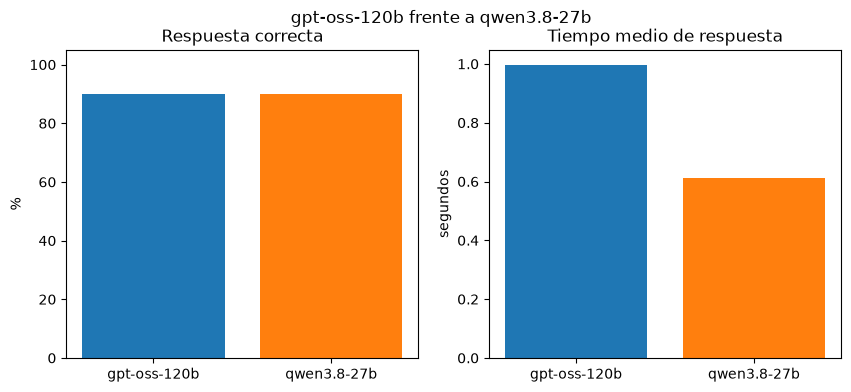

In [19]:
colores = ['tab:blue', 'tab:orange']

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(resumen.columns, resumen.loc['Respuesta correcta (%)'], color=colores)
ax[0].set_ylim(0, 105)
ax[0].set_ylabel('%')
ax[0].set_title('Respuesta correcta')
ax[1].bar(resumen.columns, resumen.loc['Tiempo medio (s)'], color=colores)
ax[1].set_ylabel('segundos')
ax[1].set_title('Tiempo medio de respuesta')
fig.suptitle('gpt-oss-120b frente a qwen3.8-27b')
plt.savefig('../outputs/comparativa_modelos.png', bbox_inches='tight')
plt.show()

# Segundo juez: Gemini Decision 1

Como el juez principal es un modelo pequeño, calificamos las mismas 20 respuestas con un segundo juez de otro tipo. En las mejoras futuras del README se proponía justo esto: un juez de tipo decisión, que además de la calificación diera una confianza. Google publicó uno el 11 de noviembre de 2026, **Gemini Decision 1**, con un nivel gratuito amplio (10.000 peticiones al día).

## Qué es un modelo de decisión

Un LLM normal escribe texto: al juez Flash-Lite le pedimos una palabra y luego buscamos esa palabra en lo que ha escrito. Un modelo de decisión no escribe nada. Recibe un texto y una pregunta cerrada, y devuelve directamente un número: la probabilidad de que la respuesta sea sí.

Aquí la pregunta es de tipo noul (sí o no): si la RESPUESTA contiene la información esencial de la REFERENCIA y no la contradice. En criteria le describimos qué cuenta como sí (true_description) y qué cuenta como no (false_description), con el mismo criterio que usa el otro juez.

Tiene dos ventajas: es muy rápido y da un número en vez de una palabra. Una probabilidad cerca de 0 o de 1 indica que lo tiene claro; una cerca de 0,5 indica una respuesta dudosa, que conviene revisar a mano.

La función lleva la misma protección que el otro juez: tiempo máximo de 30 segundos y hasta 3 intentos.

In [20]:
def juzgar_decision(pregunta, respuesta, referencia):
    mensaje = 'PREGUNTA: ' + pregunta + '\nREFERENCIA: ' + referencia + '\nRESPUESTA: ' + respuesta
    preguntas_decision = {'correcta': {
        'type': 'noul',
        'instructions': '¿La RESPUESTA contiene la información esencial de la REFERENCIA y no la contradice?',
        'criteria': {
            'true_description': 'La respuesta contiene la información esencial de la referencia y no la contradice.',
            'false_description': 'A la respuesta le falta un dato clave, contradice la referencia, o dice que no lo sabe cuando la referencia sí da una respuesta.'}}}
    salida = None
    intentos = 0
    while salida is None and intentos < 3:
        try:
            salida = cliente_google.decisions.create(
                model='gemini-decision-1',
                input=mensaje,
                questions=preguntas_decision,
                timeout=30)
        except Exception as error:
            print('El juez ha fallado (' + type(error).__name__ + '); esperamos 15 segundos y lo reintentamos')
            time.sleep(15)
        intentos = intentos + 1
    if salida is None:
        return np.nan
    return salida.answers['correcta'].noul

Calificamos las 20 respuestas y guardamos la probabilidad de cada una junto a la nota del juez Flash-Lite.

In [21]:
prob_gpt = []
prob_qwen = []
for i in range(len(resultados)):
    prob_gpt.append(juzgar_decision(resultados['pregunta'][i], resultados['texto_gpt'][i], resultados['referencia'][i]))
    prob_qwen.append(juzgar_decision(resultados['pregunta'][i], resultados['texto_qwen'][i], resultados['referencia'][i]))

resultados['prob_gpt'] = prob_gpt
resultados['prob_qwen'] = prob_qwen
resultados[['pregunta', 'resp_gpt', 'prob_gpt', 'resp_qwen', 'prob_qwen']].round(2)

,pregunta,resp_gpt,prob_gpt,resp_qwen,prob_qwen
0,¿Abre el taller los sábados?,1,0.98,1,0.99
1,¿Cuándo es gratis el coche de sustitución?,1,0.81,1,0.91
2,¿Cuánto dura la garantía de una reparación en ...,1,0.96,1,0.95
3,¿Dónde tiene que poner un taller la placa-dist...,1,0.97,1,0.95
4,¿En qué plazo hay que reparar los defectos lev...,1,0.90,1,0.75
5,¿Qué resultado tiene la ITV si se detecta un d...,1,0.96,1,0.96
6,¿Cómo puedo consultar si mi coche tiene una ll...,1,0.98,1,0.96
7,¿Qué estaciones ITV hay en la provincia de Val...,1,0.92,1,0.95
8,¿Hay alguna estación ITV en Utrera?,0,0.03,0,0.04
9,¿Quién ganó el Mundial de fútbol de 2010?,1,0.98,1,0.98


## ¿Coinciden los dos jueces?

Pasamos la probabilidad a nota con un corte en 0,5 (de 0,5 hacia arriba, correcta), contamos en cuántas respuestas coincide con Flash-Lite y listamos las que no, que son las primeras que hay que revisar a mano.

In [22]:
resultados['decision_gpt'] = (resultados['prob_gpt'] >= 0.5).astype(int)
resultados['decision_qwen'] = (resultados['prob_qwen'] >= 0.5).astype(int)

coinciden = (resultados['decision_gpt'] == resultados['resp_gpt']).sum() + (resultados['decision_qwen'] == resultados['resp_qwen']).sum()
print('Los dos jueces coinciden en', coinciden, 'de', 2 * len(resultados), 'respuestas')
print()
print('Respuesta correcta según Decision 1 (%):')
print('  gpt-oss-120b:', resultados['decision_gpt'].mean() * 100)
print('  qwen3.8-27b:', resultados['decision_qwen'].mean() * 100)
print()
for i in range(len(resultados)):
    if resultados['decision_gpt'][i] != resultados['resp_gpt'][i]:
        print('No coinciden en la respuesta de gpt-oss-120b a:', resultados['pregunta'][i])
    if resultados['decision_qwen'][i] != resultados['resp_qwen'][i]:
        print('No coinciden en la respuesta de qwen3.8-27b a:', resultados['pregunta'][i])

Los dos jueces coinciden en 20 de 20 respuestas

Respuesta correcta según Decision 1 (%):
  gpt-oss-120b: 90.0
  qwen3.8-27b: 90.0



# Ejemplos lado a lado

Tres preguntas con la respuesta completa de cada modelo: la garantía, las estaciones de Valladolid y la pregunta fuera de tema. Son las mismas respuestas que se han evaluado arriba.

In [23]:
for i in [2, 7, 9]:
    print('PREGUNTA:', resultados['pregunta'][i])
    print()
    print('--- gpt-oss-120b (' + str(round(resultados['seg_gpt'][i], 2)) + ' s) ---')
    print(resultados['texto_gpt'][i])
    print()
    print('--- qwen3.8-27b (' + str(round(resultados['seg_qwen'][i], 2)) + ' s) ---')
    print(resultados['texto_qwen'][i])
    print()
    print('=' * 60)
    print()

PREGUNTA: ¿Cuánto dura la garantía de una reparación en un taller?

--- gpt-oss-120b (0.98 s) ---
La garantía de una reparación en un taller es de **tres meses o 2 000 kilómetros**, lo que ocurra antes. En el caso de vehículos industriales, la garantía es de **quince días o 2 000 kilómetros**, lo que ocurra antes【1†L2-L4】【3†L9-L11】.  

Fuentes: rd_1457_1986_talleres_reparacion.pdf, faq_taller.md.

--- qwen3.8-27b (0.38 s) ---
La garantía de una reparación dura tres meses o 2.000 kilómetros, lo que ocurra antes. En el caso de vehículos industriales, la garantía es de quince días o 2.000 kilómetros.

Fuentes: rd_1457_1986_talleres_reparacion.pdf, faq_taller.md


PREGUNTA: ¿Qué estaciones ITV hay en la provincia de Valladolid?

--- gpt-oss-120b (2.09 s) ---
**Estaciones ITV en la provincia de Valladolid (según el registro 2026):**

| Código | Tipo | Localización |
|--------|------|--------------|
| ITV 4701 | Concesión (GRUPO ITEVELESA, S.L.) | P.I. Argales, C/. Vázquez de Menchaca, 2, **

# Revisión manual de las respuestas

Como en el cuaderno 04, mostramos todas las respuestas para revisarlas a mano, cada una con la nota del juez Flash-Lite (1 correcta, 0 incorrecta) y la probabilidad de Decision 1.

In [24]:
for i in range(len(resultados)):
    print(i + 1, resultados['pregunta'][i])
    print('GPT-OSS-120B (juez ' + str(resultados['resp_gpt'][i]) + ', Decision 1 ' + str(round(resultados['prob_gpt'][i], 2)) + '):',
          resultados['texto_gpt'][i][:400])
    print('QWEN3.8-27B (juez ' + str(resultados['resp_qwen'][i]) + ', Decision 1 ' + str(round(resultados['prob_qwen'][i], 2)) + '):',
          resultados['texto_qwen'][i][:400])
    print('-' * 60)

1 ¿Abre el taller los sábados?
GPT-OSS-120B (juez 1, Decision 1 0.98): Sí, el taller abre los sábados de 9:00 a 13:00 (solo para entregas y recogidas).  
Fuente: faq_taller.md.
QWEN3.8-27B (juez 1, Decision 1 0.99): Sí, el taller abre los sábados de 9:00 a 13:00, exclusivamente para entregas y recogidas.

Fuente: faq_taller.md
------------------------------------------------------------
2 ¿Cuándo es gratis el coche de sustitución?
GPT-OSS-120B (juez 1, Decision 1 0.81): El coche de sustitución es gratuito cuando la reparación supera los 300 € (y la reparación dura más de un día; hay que reservarlo al pedir cita). En reparaciones de menor importe tiene un coste de 20 €/día.  

**Fuente:** faq_taller.md
QWEN3.8-27B (juez 1, Decision 1 0.91): El coche de sustitución es gratuito en reparaciones de más de 300 €.

Fuente: faq_taller.md
------------------------------------------------------------
3 ¿Cuánto dura la garantía de una reparación en un taller?
GPT-OSS-120B (juez 1, Decision 1 0.96)

# Conclusiones

- **Acierto:** empate. Los dos modelos responden bien 9 de las 10 preguntas (90 %). La única que fallan es la misma, la de Utrera, y no es culpa del LLM: la búsqueda no trae el trozo con la estación 4131 (el acierto de recuperación es del 88,9 %, igual que en el cuaderno 04) y los dos contestan No lo sé, que es lo que se les pide cuando el contexto no tiene la respuesta.
- **Tiempo:** qwen3.8-27b es más rápido: 0,61 segundos de media frente a 1,00, y 0,38 de mediana frente a 0,91. Aun así los dos responden en torno a un segundo o menos, así que en un chat la diferencia apenas se nota.
- **Por qué tarda menos:** escribe muchos menos tokens de salida (78 de media frente a 245). gpt-oss-120b razona antes de contestar y esos tokens también cuentan, aunque no se vean en la respuesta; qwen3.8-27b contesta directamente.
- **Estilo de las respuestas:** gpt-oss-120b da más detalle y más formato (una tabla en la pregunta de Valladolid, el precio de 20 € al día en la del coche de sustitución), y en dos respuestas deja marcas de cita entre corchetes que no significan nada para el usuario (se ven en la pregunta de la garantía). qwen3.8-27b es más escueto y copia el texto tal cual viene en los documentos, con las mayúsculas del CSV.
- **Los dos jueces coinciden** en las 20 respuestas. Entre las correctas, las probabilidades más bajas de Decision 1 son 0,75 y 0,81; ninguna se acerca a 0,5, así que no hay respuestas dudosas. Al leer las 20 respuestas, las notas parecen correctas: en la de Valladolid los dos modelos listan las 7 estaciones, incluida Peñafiel.
- **Límites de esta comparación:** 10 preguntas son pocas. Un empate a 9 no demuestra que los dos modelos sean iguales en general, solo que en estas preguntas el modelo pequeño no pierde acierto. El tiempo está medido una sola vez por pregunta y depende de cómo estén los servidores de Groq en ese momento. Además, el juez principal es un modelo pequeño (Flash-Lite), aunque el segundo juez coincide con él en todo.
- **Qué modelo usar:** para este asistente, qwen3.8-27b da el mismo acierto con respuestas más cortas y más rápidas, y gpt-oss-120b da respuestas más completas. Como qwen3.8-27b está en preview en Groq y pueden retirarlo, gpt-oss-120b sigue siendo la opción más segura para dejar el asistente funcionando, con qwen3.8-27b como alternativa si se quiere más rapidez.
- **Lo que limita al asistente sigue siendo la búsqueda,** no el modelo: cambiar de LLM no arregla Utrera. Es la misma lección del cuaderno 04.